<a href="https://colab.research.google.com/github/Shivaji-Vasanth/Deep-Learning/blob/main/Exp28.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Experiment 28: Deep Boltzmann Machine (DBM) Simulation

Task 1: Build a Two-Hidden-Layer DBM

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import expit
from sklearn.datasets import load_digits

np.random.seed(42)
X = (load_digits().data[:500] / 16 > 0.5).astype(float)

class DBM:
    def __init__(self):
        self.W1 = np.random.randn(64, 32) * 0.05
        self.W2 = np.random.randn(32, 16) * 0.05
        self.a = np.zeros(64)
        self.b1 = np.zeros(32)
        self.b2 = np.zeros(16)

    def mean_field(self, v, steps=5):
        h1 = np.full((len(v), 32), 0.5)
        h2 = np.full((len(v), 16), 0.5)
        for _ in range(steps):
            h1 = expit(v @ self.W1 + h2 @ self.W2.T + self.b1)
            h2 = expit(h1 @ self.W2 + self.b2)
        return h1, h2

    def gibbs(self, v, steps=1):
        for _ in range(steps):
            h1, h2 = self.mean_field(v)
            h1 = (np.random.rand(*h1.shape) < h1).astype(float)
            h2 = (np.random.rand(*h2.shape) < h2).astype(float)
            p = expit(h1 @ self.W1.T + self.a)
            v = (np.random.rand(*p.shape) < p).astype(float)
        return v

dbm = DBM()
print("Two-layer DBM initialized")


Two-layer DBM initialized


Task 2: Train Using Approximate Learning

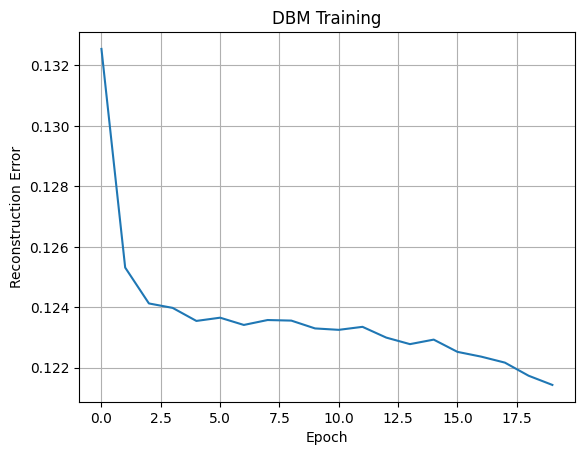

In [2]:

lr = 0.05
errors = []

for epoch in range(20):
    for batch in np.array_split(X[np.random.permutation(len(X))], 10):
        h1, h2 = dbm.mean_field(batch)

        negative = dbm.gibbs(batch, steps=2)
        n1, n2 = dbm.mean_field(negative)

        dbm.W1 += lr * (batch.T @ h1 - negative.T @ n1) / len(batch)
        dbm.W2 += lr * (h1.T @ h2 - n1.T @ n2) / len(batch)

        dbm.a += lr * (batch - negative).mean(axis=0)
        dbm.b1 += lr * (h1 - n1).mean(axis=0)
        dbm.b2 += lr * (h2 - n2).mean(axis=0)

    h1, _ = dbm.mean_field(X)
    recon = expit(h1 @ dbm.W1.T + dbm.a)
    errors.append(np.mean((X - recon)**2))

plt.plot(errors)
plt.xlabel("Epoch")
plt.ylabel("Reconstruction Error")
plt.title("DBM Training")
plt.grid(True)
plt.show()


Task 3: Visualize Filters and Hidden Activations

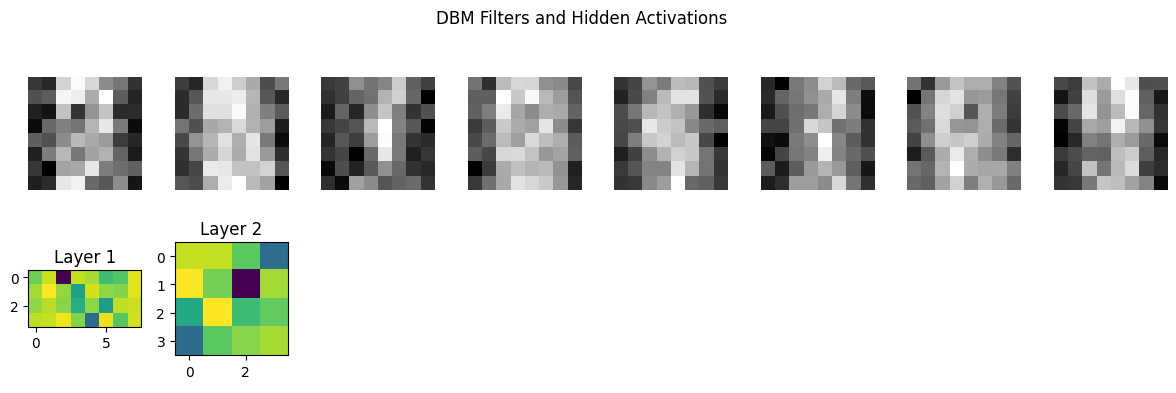

In [3]:

fig, axes = plt.subplots(2, 8, figsize=(12, 4))

for i in range(8):
    axes[0, i].imshow(dbm.W1[:, i].reshape(8, 8), cmap='gray')
    axes[0, i].axis('off')

h1, h2 = dbm.mean_field(X[:1])

axes[1, 0].imshow(h1.reshape(4, 8), cmap='viridis')
axes[1, 0].set_title("Layer 1")

axes[1, 1].imshow(h2.reshape(4, 4), cmap='viridis')
axes[1, 1].set_title("Layer 2")

for ax in axes[1, 2:]:
    ax.axis('off')

plt.suptitle("DBM Filters and Hidden Activations")
plt.tight_layout()
plt.show()


Task 4: Generate Samples and Reconstructions

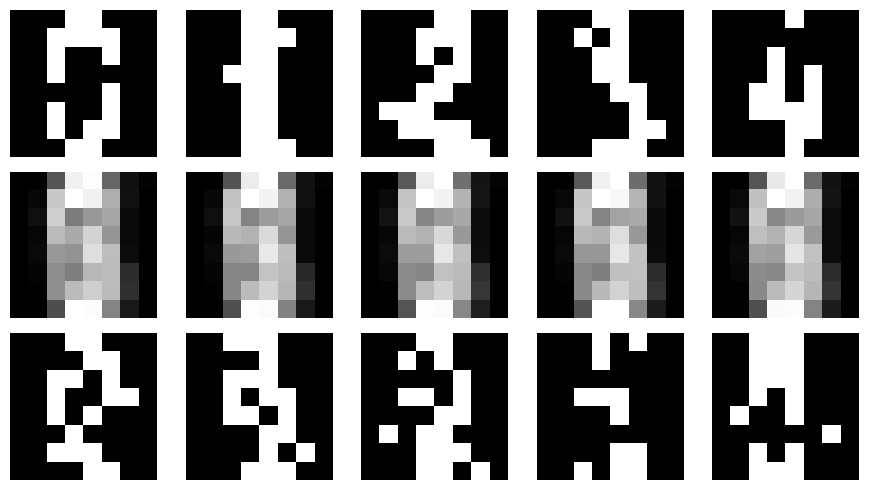

In [4]:

original = X[:5]
h1, _ = dbm.mean_field(original)
reconstructed = expit(h1 @ dbm.W1.T + dbm.a)

generated = dbm.gibbs(
    np.random.randint(0, 2, (5, 64)).astype(float),
    steps=100
)

fig, axes = plt.subplots(3, 5, figsize=(9, 5))

for i in range(5):
    for j, data in enumerate([original, reconstructed, generated]):
        axes[j, i].imshow(data[i].reshape(8, 8), cmap='gray')
        axes[j, i].axis('off')

for j, title in enumerate(['Original', 'Reconstructed', 'Generated']):
    axes[j, 0].set_ylabel(title)

plt.tight_layout()
plt.show()


Task 5: Compare DBM with a Single-Layer RBM

           Model  Reconstruction MSE
Single-Layer RBM              0.1240
   Two-Layer DBM              0.1214


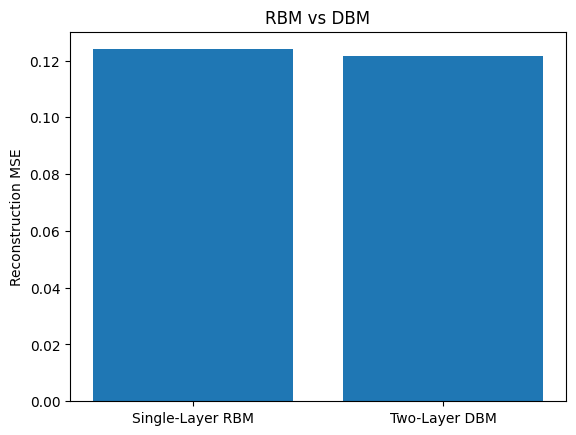

In [5]:

from sklearn.neural_network import BernoulliRBM
import pandas as pd

rbm = BernoulliRBM(
    n_components=32,
    learning_rate=0.05,
    n_iter=20,
    batch_size=50,
    random_state=42
)

rbm.fit(X)

rbm_hidden = rbm.transform(X)
rbm_recon = expit(
    rbm_hidden @ rbm.components_ + rbm.intercept_visible_
)

dbm_hidden, _ = dbm.mean_field(X)
dbm_recon = expit(dbm_hidden @ dbm.W1.T + dbm.a)

comparison = pd.DataFrame({
    'Model': ['Single-Layer RBM', 'Two-Layer DBM'],
    'Reconstruction MSE': [
        np.mean((X - rbm_recon)**2),
        np.mean((X - dbm_recon)**2)
    ]
})

print(comparison.round(4).to_string(index=False))

plt.bar(comparison['Model'], comparison['Reconstruction MSE'])
plt.ylabel('Reconstruction MSE')
plt.title('RBM vs DBM')
plt.show()
